In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3

In [8]:
df = pd.read_csv(
    "../data/cleaned/Amazon_Sale_Report_Cleaned.csv",
    low_memory=False
)
print("Cleaned dataset loaded!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Cleaned dataset loaded!
Rows: 128975
Columns: 23


In [9]:
# Order Status Analysis

status_counts = df["Status"].value_counts()

print(status_counts)

Status
Shipped                          77804
Shipped - Delivered to Buyer     28769
Cancelled                        18332
Shipped - Returned to Seller      1953
Shipped - Picked Up                973
Pending                            658
Pending - Waiting for Pick Up      281
Shipped - Returning to Seller      145
Shipped - Out for Delivery          35
Shipped - Rejected by Buyer         11
Shipping                             8
Shipped - Lost in Transit            5
Shipped - Damaged                    1
Name: count, dtype: int64


In [10]:
# Product Category Analysis

category_counts = df["Category"].value_counts()

print(category_counts)

Category
Set              50284
kurta            49877
Western Dress    15500
Top              10622
Ethnic Dress      1159
Blouse             926
Bottom             440
Saree              164
Dupatta              3
Name: count, dtype: int64


In [11]:
# Total quantity sold

total_quantity = df["Qty"].sum()

print("Total Quantity:", total_quantity)

Total Quantity: 116649


In [12]:
# Total Revenue

total_revenue = df["Amount"].sum()

print("Total Revenue:", total_revenue)

Total Revenue: 78592678.3


In [13]:
#total number of unique orders, total quantity, total revenue, total categories, and total states

print("Total Orders:", df["Order ID"].nunique())
print("Total Quantity:", df["Qty"].sum())
print("Total Revenue:", df["Amount"].sum())
print("Total Categories:", df["Category"].nunique())
print("Total States:", df["ship-state"].nunique())

Total Orders: 120378
Total Quantity: 116649
Total Revenue: 78592678.3
Total Categories: 9
Total States: 70


In [14]:
# Monthly Sales Analysis

df["Date"] = pd.to_datetime(df["Date"], errors="coerce")

monthly_sales = (
    df.groupby(df["Date"].dt.to_period("M"))["Amount"]
      .sum()
      .reset_index()
)

monthly_sales["Date"] = monthly_sales["Date"].astype(str)

print(monthly_sales)

      Date       Amount
0  2022-03    101683.85
1  2022-04  28838708.32
2  2022-05  26226476.75
3  2022-06  23425809.38


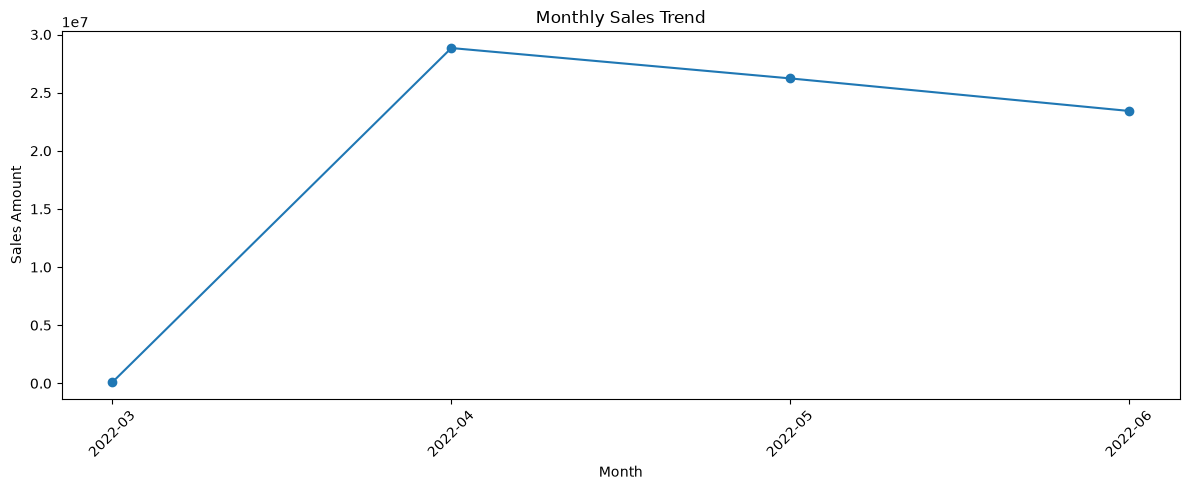

In [15]:
# Monthly Sales Chart
plt.figure(figsize=(12, 5))

plt.plot(
    monthly_sales["Date"],
    monthly_sales["Amount"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [16]:
#Category-wise Sales

category_sales = (
    df.groupby("Category")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(category_sales)


Category
Set              39204124.03
kurta            21299546.70
Western Dress    11216072.69
Top               5347792.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: Amount, dtype: float64


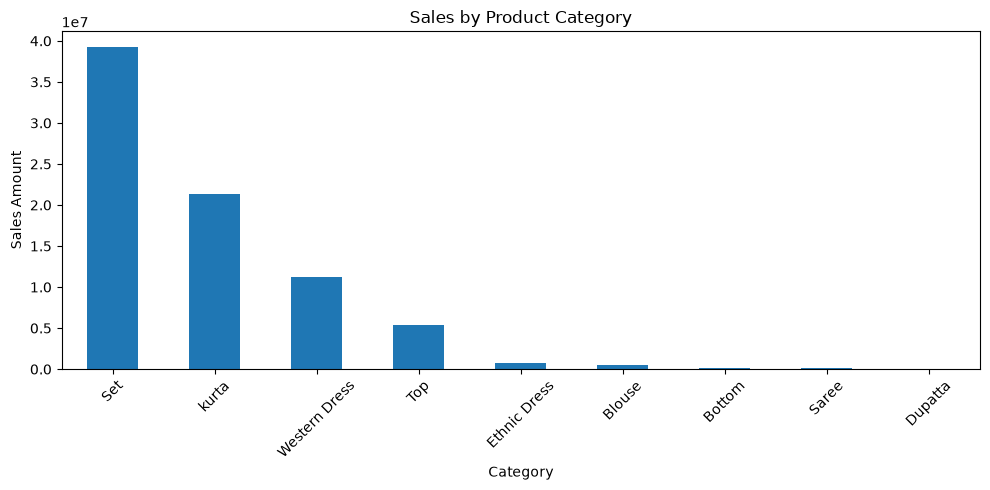

In [17]:
#Category Chart
plt.figure(figsize=(10, 5))

category_sales.plot(kind="bar")

plt.title("Sales by Product Category")
plt.xlabel("Category")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [18]:
#State-wise Sales
state_sales = (
    df.groupby("ship-state")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(state_sales.head(10))


ship-state
MAHARASHTRA       13335534.14
KARNATAKA         10481114.37
TELANGANA          6916615.65
UTTAR PRADESH      6816642.08
TAMIL NADU         6515650.11
DELHI              4235215.97
KERALA             3830227.58
WEST BENGAL        3507880.44
ANDHRA PRADESH     3219831.72
HARYANA            2882092.99
Name: Amount, dtype: float64


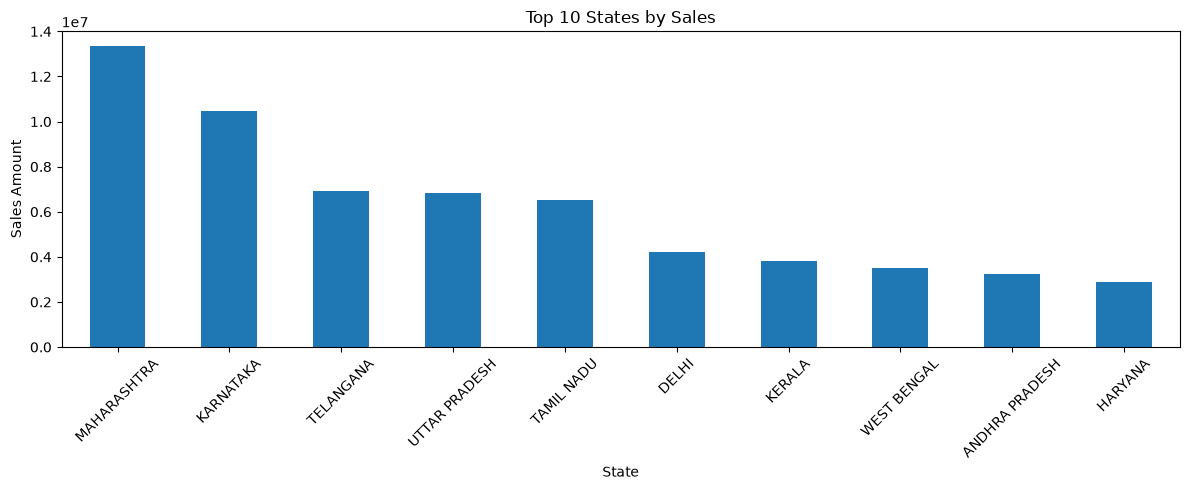

In [19]:
# State-wise Sales Analysis
plt.figure(figsize=(12, 5))

state_sales.head(10).plot(kind="bar")

plt.title("Top 10 States by Sales")
plt.xlabel("State")
plt.ylabel("Sales Amount")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

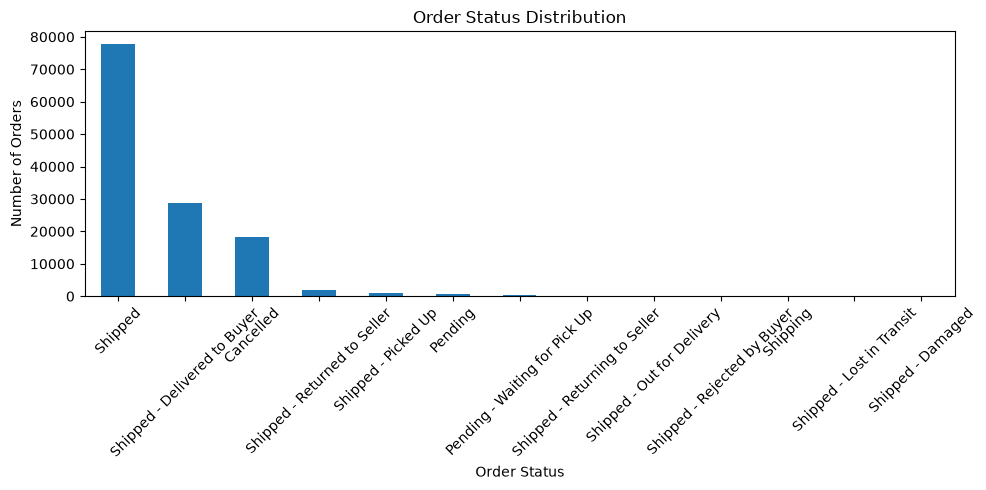

In [20]:
#Order Status Chart
status_counts = df["Status"].value_counts()

plt.figure(figsize=(10, 5))

status_counts.plot(kind="bar")

plt.title("Order Status Distribution")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [21]:
# Top 10 Best-Selling Products

top_products = (
    df.groupby("Style")["Qty"]
      .sum()
      .sort_values(ascending=False)
      .head(10)
)

print(top_products)

Style
JNE3797    3692
JNE3405    2067
SET268     1731
J0230      1710
J0341      1471
J0003      1390
SET324     1152
SET345     1134
JNE3373    1070
JNE3399     971
Name: Qty, dtype: int64


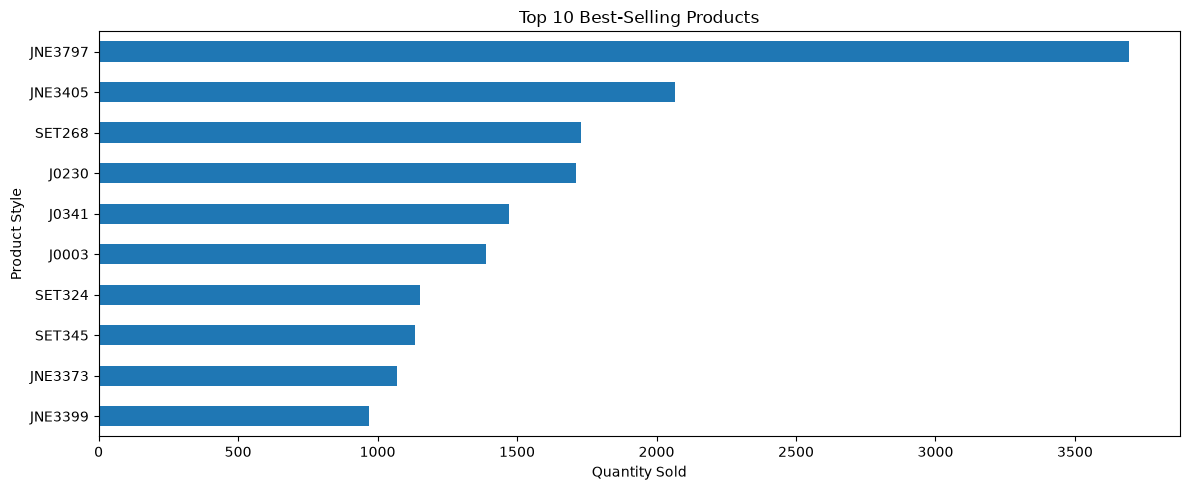

In [22]:
#Top Products ka Chart
plt.figure(figsize=(12, 5))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Quantity Sold")
plt.ylabel("Product Style")
plt.tight_layout()
plt.show()

Size
M       20447
L       20000
XL      18923
XXL     16516
S       15331
3XL     13524
XS       9943
6XL       688
5XL       513
4XL       398
Free      366
Name: Qty, dtype: int64


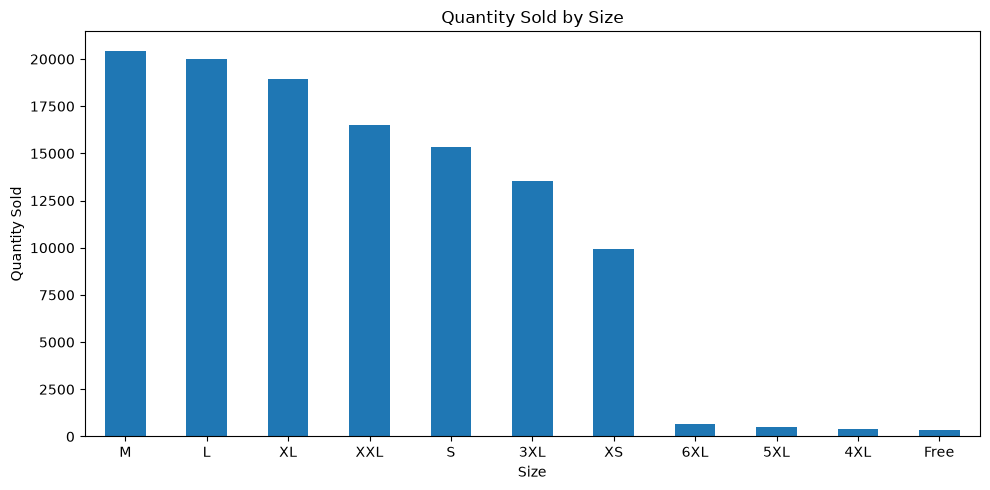

In [23]:
# Sales by Size

size_sales = (
    df.groupby("Size")["Qty"]
      .sum()
      .sort_values(ascending=False)
)

print(size_sales)
plt.figure(figsize=(10, 5))

size_sales.plot(kind="bar")

plt.title("Quantity Sold by Size")
plt.xlabel("Size")
plt.ylabel("Quantity Sold")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Fulfilment
Amazon      89698
Merchant    39277
Name: count, dtype: int64


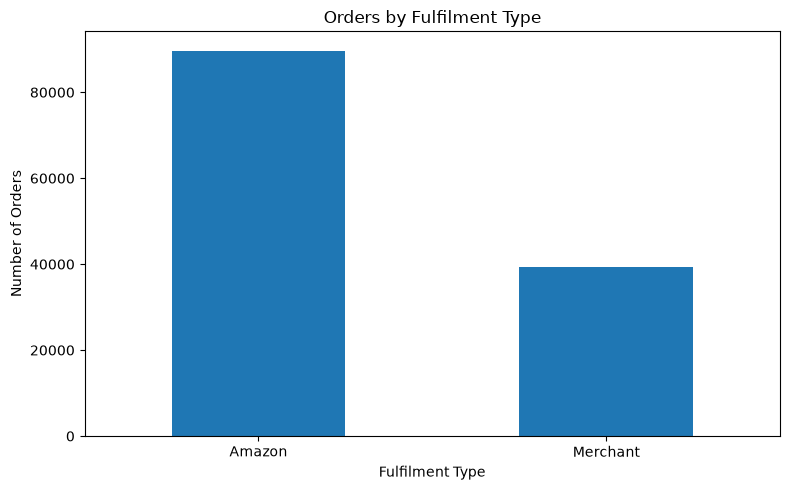

In [24]:
# Fulfilment Analysis

fulfilment_counts = df["Fulfilment"].value_counts()

print(fulfilment_counts)
plt.figure(figsize=(8, 5))

fulfilment_counts.plot(kind="bar")

plt.title("Orders by Fulfilment Type")
plt.xlabel("Fulfilment Type")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


Sales Channel 
Amazon.in     128851
Non-Amazon       124
Name: count, dtype: int64


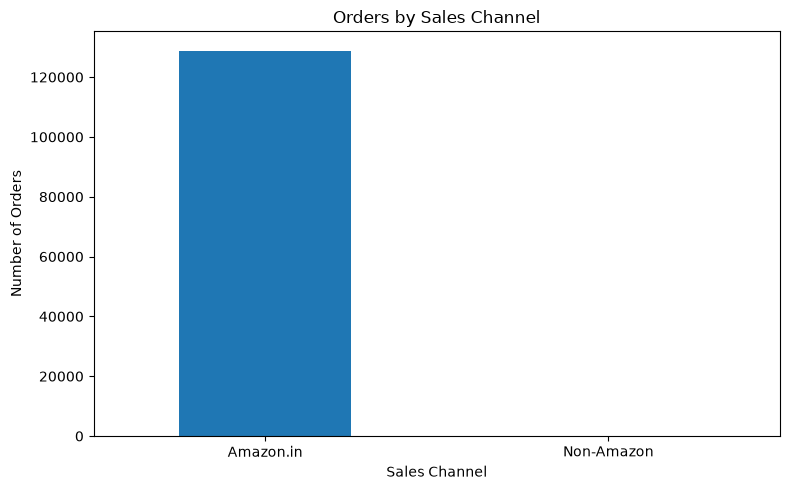

<Figure size 1000x500 with 0 Axes>

<Figure size 1000x500 with 0 Axes>

In [25]:
# Sales Channel Analysis

channel_counts = df["Sales Channel "].value_counts()

print(channel_counts)
plt.figure(figsize=(8, 5))

channel_counts.plot(kind="bar")

plt.title("Orders by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
plt.figure(figsize=(10, 5))

In [26]:
# Cancelled Orders
cancelled_orders = df[df["Status"].str.contains("Cancel", case=False, na=False)]

print("Cancelled Orders:", len(cancelled_orders))

Cancelled Orders: 18332


In [27]:
# Cancelled Order Percentage
total_orders = len(df)

cancelled_percentage = (
    len(cancelled_orders) / total_orders
) * 100

print("Cancelled Order Percentage:", round(cancelled_percentage, 2), "%")

Cancelled Order Percentage: 14.21 %


In [28]:
# Revenue by Category
category_revenue = (
    df.groupby("Category")["Amount"]
      .sum()
      .sort_values(ascending=False)
)

print(category_revenue)

Category
Set              39204124.03
kurta            21299546.70
Western Dress    11216072.69
Top               5347792.30
Ethnic Dress       791217.66
Blouse             458408.18
Bottom             150667.98
Saree              123933.76
Dupatta               915.00
Name: Amount, dtype: float64


In [29]:
#Top 10 States by Orders
top_states = (
    df["ship-state"]
      .value_counts()
      .head(10)
)

print(top_states)

ship-state
MAHARASHTRA       22260
KARNATAKA         17326
TAMIL NADU        11483
TELANGANA         11330
UTTAR PRADESH     10638
DELHI              6782
KERALA             6585
WEST BENGAL        5963
ANDHRA PRADESH     5430
Gujarat            4489
Name: count, dtype: int64


In [30]:
#Save Analysis Results
analysis_summary = pd.DataFrame({
    "Metric": [
        "Total Records",
        "Unique Orders",
        "Total Quantity",
        "Total Revenue",
        "Average Order Value",
        "Cancelled Orders"
    ],
    "Value": [
        len(df),
        df["Order ID"].nunique(),
        df["Qty"].sum(),
        df["Amount"].sum(),
        df["Amount"].mean(),
        len(cancelled_orders)
    ]
})

analysis_summary

,Metric,Value
0,Total Records,1.289750e+05
1,Unique Orders,1.203780e+05
2,Total Quantity,1.166490e+05
3,Total Revenue,7.859268e+07
4,Average Order Value,6.485615e+02
5,Cancelled Orders,1.833200e+04


In [31]:
import pandas as pd

if "df" not in globals():
    df = pd.read_csv(
        "../data/cleaned/Amazon_Sale_Report_Cleaned.csv",
        low_memory=False
    )

total_orders = df["Order ID"].nunique()
total_quantity = df["Qty"].sum()
total_revenue = df["Amount"].sum()

print("Total Orders:", total_orders)
print("Total Quantity Sold:", total_quantity)
print("Total Revenue:", round(total_revenue, 2))

Total Orders: 120378
Total Quantity Sold: 116649
Total Revenue: 78592678.3


In [32]:
average_order_value = total_revenue / total_orders

print("Average Order Value:", round(average_order_value, 2))

Average Order Value: 652.88


In [33]:
analysis_summary = pd.DataFrame({
    "Metric": [
        "Total Orders",
        "Total Quantity Sold",
        "Total Revenue",
        "Average Order Value"
    ],
    "Value": [
        total_orders,
        total_quantity,
        total_revenue,
        average_order_value
    ]
})

analysis_summary

,Metric,Value
0,Total Orders,1.203780e+05
1,Total Quantity Sold,1.166490e+05
2,Total Revenue,7.859268e+07
3,Average Order Value,6.528824e+02


In [34]:


conn = sqlite3.connect("../data/amazon_sales.db")

df.to_sql(
    "amazon_sales",
    conn,
    if_exists="replace",
    index=False
)

print("SQL database created successfully!")

SQL database created successfully!


In [ ]:
#-- 1. Total Orders

query = """
SELECT COUNT(DISTINCT "Order ID") AS total_orders
FROM amazon_sales;
"""

result = pd.read_sql_query(query, conn)

result

,total_orders
0,120378


In [36]:
query = """
SELECT SUM("Amount") AS total_revenue
FROM amazon_sales;
"""

result = pd.read_sql_query(query, conn)

result

,total_revenue
0,78592678.3


In [37]:
#Har product category ki total sales/revenue, highest se lowest order me.
query = """
SELECT
    "Category",
    SUM("Amount") AS total_revenue
FROM amazon_sales
GROUP BY "Category"
ORDER BY total_revenue DESC;
"""

result = pd.read_sql_query(query, conn)

result

,Category,total_revenue
0,Set,39204124.03
1,kurta,21299546.70
2,Western Dress,11216072.69
3,Top,5347792.30
4,Ethnic Dress,791217.66
5,Blouse,458408.18
6,Bottom,150667.98
7,Saree,123933.76
8,Dupatta,915.00


In [38]:
#Top 10 states by revenue nikalega, highest sales se lowest sales tak.
query = """
SELECT
    "ship-state",
    SUM("Amount") AS total_revenue
FROM amazon_sales
GROUP BY "ship-state"
ORDER BY total_revenue DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

result

,ship-state,total_revenue
0,MAHARASHTRA,13335534.14
1,KARNATAKA,10481114.37
2,TELANGANA,6916615.65
3,UTTAR PRADESH,6816642.08
4,TAMIL NADU,6515650.11
5,DELHI,4235215.97
6,KERALA,3830227.58
7,WEST BENGAL,3507880.44
8,ANDHRA PRADESH,3219831.72
9,HARYANA,2882092.99


In [39]:
#Har month ki total sales:
query = """
SELECT
    strftime('%Y-%m', Date) AS month,
    SUM("Amount") AS total_revenue
FROM amazon_sales
GROUP BY month
ORDER BY month;
"""

result = pd.read_sql_query(query, conn)

result

,month,total_revenue
0,2022-03,101683.85
1,2022-04,28838708.32
2,2022-05,26226476.75
3,2022-06,23425809.38


In [40]:
#Kaunse 10 product styles sabse zyada quantity me sell hue.
query = """
SELECT
    "Style" AS product,
    SUM("Qty") AS quantity_sold
FROM amazon_sales
GROUP BY "Style"
ORDER BY quantity_sold DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)

result

,product,quantity_sold
0,JNE3797,3692
1,JNE3405,2067
2,SET268,1731
3,J0230,1710
4,J0341,1471
5,J0003,1390
6,SET324,1152
7,SET345,1134
8,JNE3373,1070
9,JNE3399,971


In [41]:
#Database me Status ke andar Cancel/Cancelled wale orders ko count karega.
query = """
SELECT
    COUNT(DISTINCT "Order ID") AS cancelled_orders
FROM amazon_sales
WHERE LOWER(Status) LIKE '%cancel%';
"""

result = pd.read_sql_query(query, conn)

result


,cancelled_orders
0,17185


In [42]:
#Order Status Analysis
query = """
SELECT
    Status,
    COUNT(DISTINCT "Order ID") AS total_orders
FROM amazon_sales
GROUP BY Status
ORDER BY total_orders DESC;
"""

result = pd.read_sql_query(query, conn)

result

,Status,total_orders
0,Shipped,72826
1,Shipped - Delivered to Buyer,26566
2,Cancelled,17185
3,Shipped - Returned to Seller,1851
4,Shipped - Picked Up,918
5,Pending,584
6,Pending - Waiting for Pick Up,262
7,Shipped - Returning to Seller,130
8,Shipped - Out for Delivery,32
9,Shipped - Rejected by Buyer,11


In [43]:
#Size-wise Quantity Sold
query = """
SELECT
    Size,
    SUM(Qty) AS quantity_sold
FROM amazon_sales
GROUP BY Size
ORDER BY quantity_sold DESC;
"""

result = pd.read_sql_query(query, conn)

result

,Size,quantity_sold
0,M,20447
1,L,20000
2,XL,18923
3,XXL,16516
4,S,15331
5,3XL,13524
6,XS,9943
7,6XL,688
8,5XL,513
9,4XL,398


In [44]:
#Sales Channel Analysis
query = """
SELECT
    "Sales Channel ",
    COUNT(DISTINCT "Order ID") AS total_orders,
    SUM("Amount") AS total_revenue
FROM amazon_sales
GROUP BY "Sales Channel "
ORDER BY total_revenue DESC;
"""

result = pd.read_sql_query(query, conn)

result

,Sales Channel,total_orders,total_revenue
0,Amazon.in,120254,78592678.3
1,Non-Amazon,124,NaN
